# Day 2 lecture: Tableau concepts and dashboards

<p class="lead">
Periods 5 and 6 of Day 2, plus the Assignment 1 briefing in period 9. The ideas that make Tableau behave the way it does: dimensions and measures, discrete and continuous fields, aggregation and level of detail, the Marks card, filters and the order in which Tableau applies them, calculated fields, maps and dashboard actions. Each idea is explained in Tableau terms and then mirrored in Python, so you can see exactly what Tableau computes.
</p>

Tableau is a tool you learn by clicking, so this lecture is meant to be taught with Tableau Desktop open on the projector. The Python mirrors use a **synthetic bookshop chain**, "Harbour Books", made inside the notebook, and the penguins data. Lab 2 uses Tableau's Sample – Superstore; this lecture deliberately does **not**, and asks different questions, so that you build and read your own dashboard in the lab.

- **Route B (Anaconda, offline):** open this notebook from the `DATA300_GAP` folder.
- **Route A (Try JupyterLab):** upload this notebook and `data/penguins.csv`, run `%pip install seaborn` in a first cell, and change `"data/penguins.csv"` to `"penguins.csv"`.

---

## What you will be able to do

1. Explain the difference between **dimensions and measures**, and between **discrete (blue) and continuous (green)** fields, and predict what each does to a view.
2. Explain **aggregation** and the **level of detail** of a view, and when a number changes because the level of detail changed.
3. Use the **Marks card** (mark type, Color, Size, Label, Detail, Tooltip) on purpose.
4. Apply **filters** and explain Tableau's **order of operations**, including why a Top N filter can give a surprising answer.
5. Write **calculated fields** at row level and aggregate level, and use **table calculations**.
6. Build a **dashboard** with **filter and highlight actions**, and check it against a **design checklist**.
7. Read a **box plot** and a **regression line** in words a manager understands (for Assignment 1).

| Part | Topic | Period |
|---|---|---|
| 1 | Tableau's building blocks | P5 |
| 2 | Dimensions and measures, discrete and continuous | P5 |
| 3 | Aggregation and level of detail | P5 |
| 4 | The Marks card | P5 |
| 5 | Filters and the order of operations | P6 |
| 6 | Calculated fields and table calculations | P6 |
| 7 | Maps | P6 |
| 8 | Dashboards, actions and a design checklist | P6 |
| 9 | Lab 2 briefing | P6 |
| 10 | Assignment 1 briefing: reading box plots and regression lines | P9 |
| 11 | Practice, quiz and summary | Self-study |

> **Reading**
>
> Read Chapter 2 of the course reading packet on dual encoding (a chart that carries two variables at once) and on what changes when static charts become a linked, interactive dashboard. Its review questions 3 and 4 are good preparation for Lab 2.

---

## Part 1: Tableau's building blocks

| Tableau object | What it is | Python mirror |
|---|---|---|
| **Data source** | A connection to a file or database (Excel, CSV, a server), with any joins or relationships between tables | `pd.read_csv(...)`, `merge` |
| **Live or extract** | Query the source each time, or take a fast snapshot (`.hyper`) | Reading the file again, or keeping a DataFrame in memory |
| **Worksheet** | One view (chart or table) built by dragging fields onto shelves | One `groupby` plus one plot |
| **Dashboard** | Several worksheets (plus text, images, filters) arranged on one canvas, optionally linked by actions | A figure with several panels and a function that redraws them |
| **Story** | A sequence of sheets or dashboards with captions, like slides | A report |
| **Workbook** | The file holding all of the above: `.twb` (no data) or `.twbx` (**packaged**, data included) | The notebook |

The workspace has the **Data pane** on the left (fields), the **Columns and Rows shelves** at the top, the **Marks card** and the **Filters** and **Pages** shelves beside the view, **Show Me** at the top right, and tabs at the bottom for sheets, dashboards and stories. Save as **`.twbx`** when you send a workbook to someone else, so the data travels with it.

Below is the synthetic data that the Python mirrors use. One row is **one order line**: one product sub-category in one order.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.dates as mdates
import seaborn as sns

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "axes.titlesize": 11})
OI = {"orange": "#E69F00", "sky": "#56B4E9", "green": "#009E73", "blue": "#0072B2",
      "vermillion": "#D55E00", "purple": "#CC79A7"}
GREY = "#B0B0B0"

# Harbour Books: a fictional chain of 12 bookshops in four regions (synthetic data)
rng = np.random.default_rng(300)
stores = pd.DataFrame({
    "region": np.repeat(["North", "South", "East", "West"], 3),
    "store": ["Pinefield", "Stonebridge", "Frostford", "Palmhaven", "Suncove", "Riverbend",
              "Dawnport", "Eastmere", "Harbourside", "Westfall", "Sunsetvale", "Cliffton"],
})
products = pd.DataFrame({
    "category": ["Books"] * 3 + ["Stationery"] * 3 + ["Gifts"] * 3,
    "sub_category": ["Fiction", "Non-fiction", "Children's", "Notebooks", "Pens", "Art supplies",
                     "Board games", "Mugs", "Cards"],
    "unit_price": [14, 18, 11, 6, 3, 15, 32, 12, 4],
    "cost_share": [0.62, 0.60, 0.58, 0.45, 0.40, 0.55, 0.78, 0.50, 0.35],
    "weight": [22, 14, 14, 10, 8, 6, 6, 8, 12],
})
n = 9000
dates = pd.to_datetime("2023-01-01") + pd.to_timedelta(rng.integers(0, 1096, n), unit="D")
season = 1 + 0.6 * (dates.month == 12) + 0.25 * (dates.month == 9)       # December and back-to-school
keep = rng.uniform(0, 1.6, n) < season
orders = pd.DataFrame({"order_date": dates[keep]})
m = len(orders)
orders["customer_id"] = rng.integers(1, 1801, m)
orders = orders.join(stores.sample(m, replace=True, random_state=1).reset_index(drop=True))
prod = products.sample(m, replace=True, weights="weight", random_state=2).reset_index(drop=True)
orders = orders.join(prod[["category", "sub_category", "unit_price", "cost_share"]])
orders["quantity"] = rng.integers(1, 6, m)
games = orders["sub_category"] == "Board games"
orders["discount"] = np.where(games, rng.choice([0, 0.2, 0.3, 0.4], m, p=[0.3, 0.2, 0.25, 0.25]),
                              rng.choice([0, 0.1, 0.2], m, p=[0.7, 0.2, 0.1]))
list_value = orders["quantity"] * orders["unit_price"]
orders["sales"] = (list_value * (1 - orders["discount"])).round(2)                  # US dollars
orders["profit"] = (orders["sales"] - list_value * orders["cost_share"]).round(2)  # US dollars
orders = orders.drop(columns=["unit_price", "cost_share"]).sort_values("order_date").reset_index(drop=True)
print(orders.shape)
orders.head()

(5960, 10)


,order_date,customer_id,region,store,category,sub_category,quantity,discount,sales,profit
0,2023-01-01,261,South,Riverbend,Stationery,Notebooks,3,0.0,18.0,9.90
1,2023-01-01,47,West,Sunsetvale,Books,Children's,4,0.0,44.0,18.48
2,2023-01-01,654,East,Eastmere,Books,Fiction,1,0.0,14.0,5.32
3,2023-01-01,67,North,Frostford,Books,Fiction,2,0.0,28.0,10.64
4,2023-01-01,1301,West,Westfall,Stationery,Art supplies,2,0.0,30.0,13.50


---

## Part 2: Dimensions and measures, discrete and continuous

### Dimensions and measures

When Tableau connects to data it sorts each field into one of two roles:

- A **dimension** is a field you **group or slice by**: region, store, category, order date. Dimensions set how many marks the view has.
- A **measure** is a field you **aggregate**: sales, profit, quantity. Measures are summed (or averaged, counted…) within each group.

Dragging **Region** to Rows and **Sales** to Columns gives a bar per region showing `SUM(Sales)`. That is exactly a `groupby`:

region
West     50648.0
North    50959.0
East     50985.0
South    53836.0
Name: sales, dtype: float64


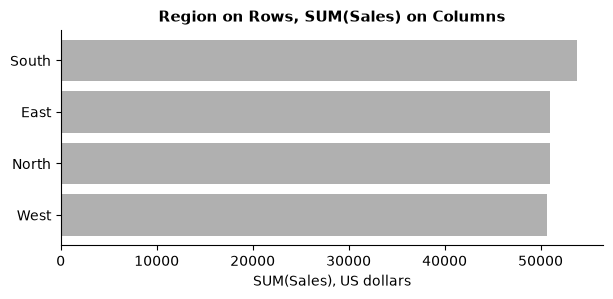

In [2]:
# Tableau: Region on Rows, SUM(Sales) on Columns
by_region = orders.groupby("region")["sales"].sum().sort_values()
print(by_region.round(0))

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.barh(by_region.index, by_region.values, color=GREY)
ax.set_xlabel("SUM(Sales), US dollars")
ax.set_title("Region on Rows, SUM(Sales) on Columns")
plt.show()

The role is a **default**, not a law. A number such as a store's postcode or a customer ID is stored as a number but is really a label: convert it to a dimension (drag it above the line in the Data pane, or right-click → **Convert to Dimension**). The rule of thumb: *if adding it up makes no sense, it is a dimension.*

### Discrete (blue) and continuous (green)

The pill colour tells you something different from the role:

- **Discrete** (blue) values are separate and distinct. On a shelf, a discrete field creates **headers** (a label for each value), and on Color it creates a **categorical** palette.
- **Continuous** (green) values form an unbroken range. On a shelf, a continuous field creates an **axis**, and on Color a **gradient**.

| | Discrete (blue) | Continuous (green) |
|---|---|---|
| **Dimension** | Region, Category; date **parts** such as MONTH(Order Date) = "May" | Date **values** such as MONTH(Order Date) = "May 2024"; a numeric dimension made continuous |
| **Measure** | SUM(Sales) turned discrete: a header per value, like a text table | SUM(Sales): an axis (the usual case) |

The most important case in practice is the **date**. Right-click a date pill and you see two lists of Year, Quarter, Month…: the **upper** list gives **date parts** (discrete), which combine the same month from every year into one header; the **lower** list gives **date values** (continuous), which keep each month of each year as its own point on a timeline. Compare them on our synthetic data:

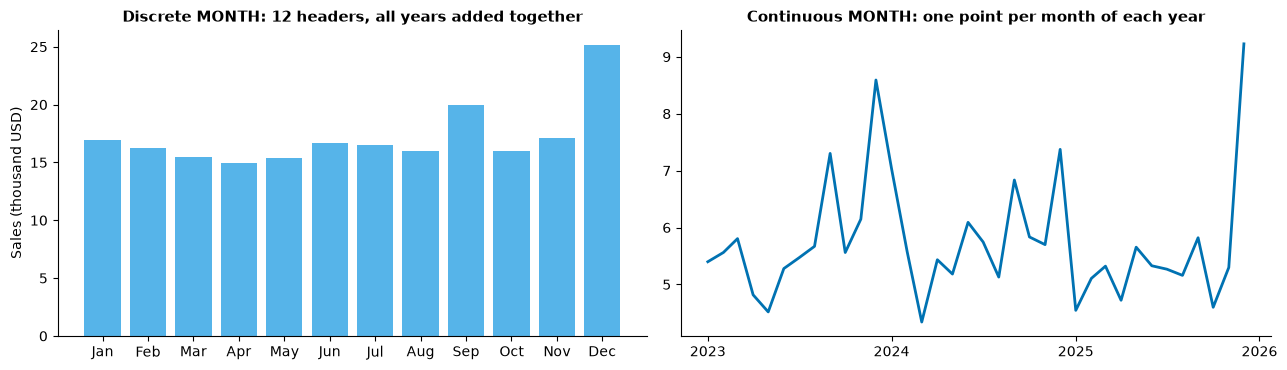

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))

# Discrete date part: MONTH(Order Date) as a blue pill -> 12 headers, every year combined
part = orders.groupby(orders["order_date"].dt.month)["sales"].sum()
axes[0].bar(pd.to_datetime(part.index, format="%m").strftime("%b"), part.values / 1000, color=OI["sky"])
axes[0].set_title("Discrete MONTH: 12 headers, all years added together")
axes[0].set_ylabel("Sales (thousand USD)")

# Continuous date value: MONTH(Order Date) as a green pill -> 36 points on a timeline
value = orders.set_index("order_date")["sales"].resample("MS").sum()
axes[1].plot(value.index, value.values / 1000, color=OI["blue"], lw=2)
axes[1].set_title("Continuous MONTH: one point per month of each year")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.tight_layout()
plt.show()

Both are correct answers to different questions. The left chart answers *"Which month of the year is usually strongest?"* (seasonality); the right chart answers *"How did sales move over time?"* (trend, and when something unusual happened). A trend line needs the **continuous** version: with the discrete version, an unusual month in one year is diluted by adding it to the same month of the other years.

> **Predict, then run.** If you put discrete YEAR and discrete MONTH next to each other on Columns, what would the chart look like, and how would it differ from the continuous version? (Hint: headers, not an axis.)

### Misconceptions

| Misconception | Better view |
|---|---|
| "Blue means dimension, green means measure." | Blue means **discrete**, green means **continuous**. Most dimensions are discrete and most measures continuous, which is why the two get confused. |
| "Dates are always continuous." | A date can be either; you choose with the pill's menu. |
| "Numbers are measures." | IDs, postcodes and years are numbers you group by, so they are dimensions. |

---

## Part 3: Aggregation and level of detail

### Aggregation

A measure on a shelf is always aggregated: `SUM` by default, changeable from the pill's menu to **AVG, MEDIAN, COUNT, COUNTD** (count distinct), **MIN, MAX** and others. Each answers a different question:

In [4]:
summary = orders.groupby("region").agg(
    SUM_sales=("sales", "sum"),
    AVG_sales_per_line=("sales", "mean"),
    MEDIAN_sales_per_line=("sales", "median"),
    COUNT_lines=("sales", "size"),
    COUNTD_customers=("customer_id", "nunique"),
).round(2)
print(summary.to_string())

        SUM_sales  AVG_sales_per_line  MEDIAN_sales_per_line  COUNT_lines  COUNTD_customers
region                                                                                     
East      50984.7               33.81                   28.0         1508              1019
North     50959.1               34.78                   28.0         1465              1026
South     53836.2               35.44                   28.0         1519              1014
West      50648.3               34.50                   28.0         1468               994


`AVG(Sales)` is the average **order line**, not the average order or the average customer: an aggregate always averages over the rows of the data source. If you need "sales per customer", that is `SUM(Sales) / COUNTD(Customer ID)`, which is a different number again.

### Level of detail

The **level of detail (LOD)** of a view is set by the dimensions in it (on Rows, Columns and the Marks card). Every aggregate is computed **once per combination** of those dimensions. Add a dimension and each mark splits into several smaller marks; the totals are re-cut, not changed.

In [5]:
lod_1 = orders.groupby("region")["profit"].sum()
lod_2 = orders.groupby(["region", "category"])["profit"].sum().unstack()
print("Level of detail = Region:\n", lod_1.round(0), "\n")
print("Level of detail = Region x Category:\n", lod_2.round(0))
print("\nRow sums of the second table equal the first:", np.allclose(lod_2.sum(axis=1), lod_1))

Level of detail = Region:
 region
East     18434.0
North    18264.0
South    19252.0
West     17986.0
Name: profit, dtype: float64 

Level of detail = Region x Category:
 category    Books   Gifts  Stationery
region                               
East      11739.0  3333.0      3363.0
North     11559.0  3095.0      3610.0
South     12032.0  3420.0      3800.0
West      11623.0  3031.0      3332.0

Row sums of the second table equal the first: True


**Disaggregating.** Unticking **Analysis → Aggregate Measures** shows every row as its own mark, which is what you want for a scatter of individual records. Here, discount against profit per order line:

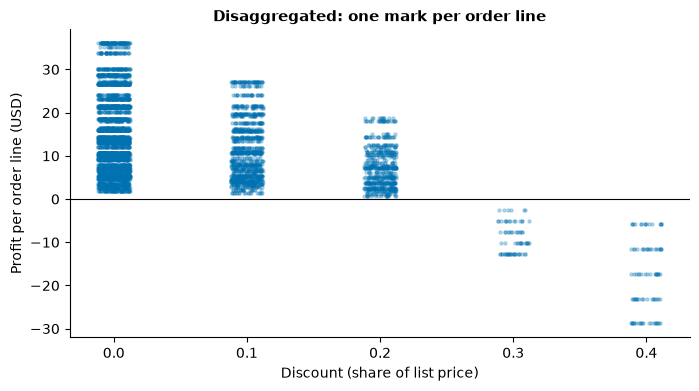

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
jit = np.random.default_rng(1).uniform(-0.012, 0.012, len(orders))
ax.scatter(orders["discount"] + jit, orders["profit"], s=5, alpha=0.25, color=OI["blue"])
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("Discount (share of list price)")
ax.set_ylabel("Profit per order line (USD)")
ax.set_title("Disaggregated: one mark per order line")
plt.show()

### Level of detail expressions

Sometimes you need a number computed at a **different** level from the view. Tableau's LOD expressions do this:

- `{FIXED [Customer ID] : MIN([Order Date])}`: each customer's first order date, whatever the view shows.
- `{INCLUDE [Customer ID] : SUM([Sales])}`: compute per customer, then aggregate up to the view (for example the average customer's spend per region).
- `{EXCLUDE [Category] : SUM([Sales])}`: ignore a dimension that is in the view (for example a region total next to each category).

In pandas, `FIXED` is a `groupby(...).transform(...)`: a group result written back to every row.

In [7]:
# {FIXED [Customer ID] : MIN([Order Date])} -> first-order year (a cohort) on every row
orders["first_order_year"] = orders.groupby("customer_id")["order_date"].transform("min").dt.year

# {INCLUDE [Customer ID] : SUM([Sales])}, then AVG in the view: average spend per customer, by region
per_customer = orders.groupby(["region", "customer_id"])["sales"].sum()
print("Average 3-year spend per customer in each region (USD):")
print(per_customer.groupby("region").mean().round(2))
print("\nCustomers by the year of their first order:")
print(orders.drop_duplicates("customer_id")["first_order_year"].value_counts().sort_index())

Average 3-year spend per customer in each region (USD):
region
East     50.03
North    49.67
South    53.09
West     50.95
Name: sales, dtype: float64

Customers by the year of their first order:
first_order_year
2023    1183
2024     407
2025     135
Name: count, dtype: int64


| Misconception | Better view |
|---|---|
| "AVG(Sales) is the average sale per customer." | It is the average per **row** of the data source, here per order line. |
| "Adding a dimension changes the totals." | It splits marks; the grand total is the same unless a filter or LOD calculation changes it. |

---

## Part 4: The Marks card

The **Marks card** controls how each mark looks. Its parts map directly onto the encodings from this morning's lecture:

| Marks card | What it encodes | matplotlib / seaborn mirror |
|---|---|---|
| **Mark type** (Automatic, Bar, Line, Area, Circle, Square, Shape, Text, Map, Pie, Gantt bar, Polygon, Density) | The kind of mark | `bar`, `plot`, `scatter`, `text`… |
| **Color** | A dimension (categorical palette) or a measure (sequential or diverging gradient) | `hue=`, `c=` with a colormap |
| **Size** | A measure, as mark area | `size=`, `s=` |
| **Label** | Text on each mark | `ax.text`, `bar_label` |
| **Detail** | Splits marks by a dimension **without** encoding it visually | Adding a column to `groupby` |
| **Tooltip** | Text shown on hover | (no static equivalent) |
| **Shape**, **Path**, **Angle** | Shape per category; drawing order of a line; pie slice angle | `marker=`, sort order, `pie` |

**Automatic** chooses a mark type from the fields: a date on Columns gives a line, a dimension and a measure give bars, two measures give circles, a geographic field gives a map. Automatic is a guess; choose deliberately.

Here is one view with Color, Size, Detail and Label all in use, on the penguins data:

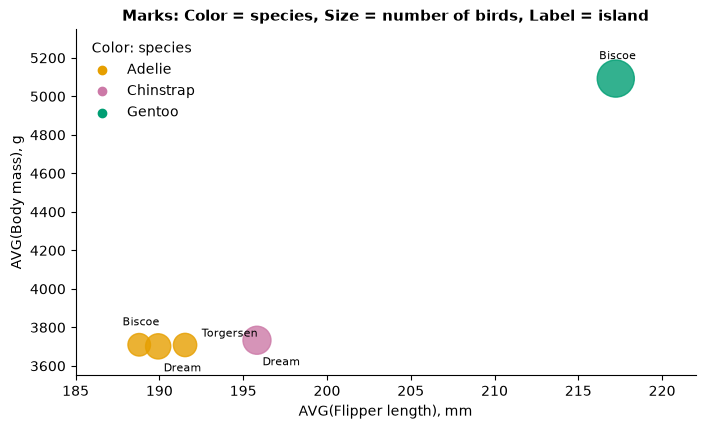

In [8]:
penguins = pd.read_csv("data/penguins.csv").dropna()    # Route A: "penguins.csv"
# Detail = island and species: one mark per island-species pair (no visual encoding of island itself)
marks = penguins.groupby(["species", "island"]).agg(
    flipper=("flipper_length_mm", "mean"), mass=("body_mass_g", "mean"), birds=("body_mass_g", "size")).reset_index()

sp_col = {"Adelie": OI["orange"], "Chinstrap": OI["purple"], "Gentoo": OI["green"]}
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(marks["flipper"], marks["mass"], s=marks["birds"] * 6,             # Size = COUNT
           color=marks["species"].map(sp_col), alpha=0.8)                       # Color = species
offsets = {"Biscoe": (-12, 14), "Dream": (4, -18), "Torgersen": (12, 6)}       # keep labels apart
for _, r in marks.iterrows():                                                    # Label = island
    ax.annotate(r["island"], (r["flipper"], r["mass"]), xytext=offsets[r["island"]],
                textcoords="offset points", fontsize=8)
for sp, c in sp_col.items():
    ax.scatter([], [], color=c, label=sp)
ax.legend(frameon=False, title="Color: species")
ax.set_xlabel("AVG(Flipper length), mm"); ax.set_ylabel("AVG(Body mass), g")
ax.set_title("Marks: Color = species, Size = number of birds, Label = island")
ax.set_xlim(185, 222); ax.set_ylim(3550, 5350)
plt.show()

Read the encodings in order of strength: position (x and y) first, then colour, then size. The three Adelie marks sit close together; the **Detail** field (island) is what split them into three. Size shows that the marks rest on very different numbers of birds, a reminder from Day 1 to show counts.

**Colour from a measure.** When a measure such as profit goes on Color, Tableau uses a **continuous gradient**. For a measure with a meaningful zero (profit, change), use a **diverging** palette and make sure its centre is **at zero**: in Tableau, **Color → Edit Colors → Advanced → Center: 0**. Otherwise the neutral colour sits at the middle of the data range and a small profit can look like a loss. The mirror in matplotlib is `TwoSlopeNorm(vcenter=0)`; Part 8 uses it.

---

## Part 5: Filters and the order of operations

### Kinds of filter

| Filter | How you make it | What it does |
|---|---|---|
| **Extract** filter | When creating an extract | Leaves rows out of the extract entirely |
| **Data source** filter | Data Source page → Filters → Add | Applies to every sheet using the source |
| **Context** filter | Right-click a filter → **Add to Context** (turns grey) | Applied first; later filters and Top N work inside it |
| **Dimension** filter | Drag a dimension to Filters | Keeps chosen members (or a Top N, a wildcard, a condition) |
| **Measure** filter | Drag a measure to Filters | Keeps marks whose **aggregate** is in a range |
| **Table calculation** filter | Filter on a table calculation | Hides marks after everything is computed |

Showing a filter (**Show Filter**) adds a control for the reader; on a dashboard, filters can apply to one sheet, several, or all sheets using the source.

### Order of operations

Tableau applies operations in a fixed order. Simplified:

1. Extract filters
2. Data source filters
3. **Context filters**
4. `FIXED` LOD expressions, sets, **Top N** and conditions
5. **Dimension filters**
6. `INCLUDE` and `EXCLUDE` LOD expressions
7. **Measure filters**
8. Table calculations, then table calculation filters

The order matters because a step can only see what the earlier steps left. The classic surprise is **Top N with another filter**. Say you want *the top 3 stores by sales in the West*. You add a Top 3 filter on Store and a filter Region = West. Both are dimension filters, so Tableau computes the Top 3 over **all** regions and then intersects with West:

In [9]:
store_sales = orders.groupby(["region", "store"])["sales"].sum().reset_index()

# Both filters at the same step: Top 3 computed on ALL stores, then intersected with West
top3_all = store_sales.nlargest(3, "sales")
print("Top 3 stores overall:\n", top3_all.to_string(index=False), "\n")
print("Top 3 filter AND Region = West (same step):")
in_west = top3_all[top3_all["region"] == "West"]
print(in_west.to_string(index=False) if len(in_west) else "  (no rows: none of the overall top 3 is in the West)")

# Region = West as a CONTEXT filter: applied first, so Top 3 is computed inside the West
west = store_sales[store_sales["region"] == "West"]
print("\nRegion = West in context, then Top 3:")
print(west.nlargest(3, "sales").to_string(index=False))

Top 3 stores overall:
 region     store   sales
 South Riverbend 19658.5
 North Frostford 18022.4
  East  Dawnport 17953.8 

Top 3 filter AND Region = West (same step):
  (no rows: none of the overall top 3 is in the West)

Region = West in context, then Top 3:
region      store   sales
  West Sunsetvale 17195.4
  West   Cliffton 16787.6
  West   Westfall 16665.3


> **Predict, then run** (above). Before running, guess how many stores the first approach returns. Whatever the count, it answers a different question ("which of the chain's top 3 are in the West?"). **Add to Context** makes the region filter run first, so the Top 3 is chosen within the West.

### Dimension filter on a measure, or measure filter?

A second classic surprise: "show me the loss-making sub-categories". Two different filters give two different answers.

In [10]:
# Measure filter: aggregate first (SUM(Profit) per sub-category), then keep the negative ones
sub = orders.groupby("sub_category")["profit"].sum()
print("Sub-categories whose TOTAL profit is negative (measure filter on SUM):")
print(sub[sub < 0].round(0).to_string() or "  none", "\n")

# Row-level filter: keep only loss-making order lines, then aggregate
loss_rows = orders[orders["profit"] < 0].groupby("sub_category")["profit"].sum()
print("Sub-categories with ANY loss-making order lines (row filter, then SUM):")
print(loss_rows.round(0).sort_values().to_string())

Sub-categories whose TOTAL profit is negative (measure filter on SUM):
sub_category
Board games   -168.0 

Sub-categories with ANY loss-making order lines (row filter, then SUM):
sub_category
Board games   -2279.0


The first answers "which sub-categories lose money overall?"; the second answers "where do loss-making lines occur, and how much do they lose?". In Tableau, dragging a measure to Filters asks how to aggregate it (**Sum** gives the first; **All values** filters rows and gives the second). Say which one you mean.

| Misconception | Better view |
|---|---|
| "Filters are applied in the order I add them." | Tableau applies them by **type**, in the fixed order above. |
| "Top N always gives me the top N of what I see." | Only if the other filters are in **context**. |
| "Filtering never changes a percentage of total." | Percent of total is a table calculation, computed after filters, so it re-bases to what is left. |

---

## Part 6: Calculated fields and table calculations

**Analysis → Create Calculated Field** (or right-click in the Data pane) opens the editor. A calculation is either **row-level** (computed for each row, then aggregated like any field) or **aggregate** (computed from aggregates, at the level of detail of the view). You cannot mix the two in one expression without aggregating everything: Tableau will report that it *cannot mix aggregate and non-aggregate arguments*.

### Profit ratio: the morning's ratio problem again

| Calculation | Type | What it gives |
|---|---|---|
| `[Profit] / [Sales]` then **AVG** | Row-level, then averaged | The mean of the line-by-line margins: every line counts equally |
| `SUM([Profit]) / SUM([Sales])` | Aggregate | Total profit ÷ total sales: every dollar counts equally |

In [11]:
orders["line_margin"] = orders["profit"] / orders["sales"]           # row-level calculated field
g = orders.groupby("category")
compare = pd.DataFrame({
    "AVG([Profit]/[Sales])": g["line_margin"].mean(),
    "SUM([Profit])/SUM([Sales])": g["profit"].sum() / g["sales"].sum(),
})
print(compare.map("{:.1%}".format).to_string())

           AVG([Profit]/[Sales]) SUM([Profit])/SUM([Sales])
category                                                   
Books                      36.8%                      37.0%
Gifts                      43.4%                      25.6%
Stationery                 51.7%                      48.0%


The usual business definition of **profit ratio** is the aggregate one, `SUM([Profit]) / SUM([Sales])`: a large order matters more than a small one. Format it as a percentage (right-click → **Default Properties → Number Format**).

### Logic, dates and strings

Three more patterns you will use often, with their pandas mirrors:

```
// Discount band (row-level, a new dimension)
IF [Discount] = 0 THEN "None"
ELSEIF [Discount] <= 0.2 THEN "Up to 20%"
ELSE "Over 20%" END

// Days since the customer's first order (an LOD inside a row-level calculation)
DATEDIFF('day', {FIXED [Customer ID] : MIN([Order Date])}, [Order Date])

// Profitable? (aggregate, at the level of the view)
IF SUM([Profit]) >= 0 THEN "Profit" ELSE "Loss" END
```

In [12]:
orders["discount_band"] = pd.cut(orders["discount"], [-0.01, 0, 0.2, 1], labels=["None", "Up to 20%", "Over 20%"])
first = orders.groupby("customer_id")["order_date"].transform("min")
orders["days_since_first"] = (orders["order_date"] - first).dt.days

band = orders.groupby("discount_band", observed=True).agg(lines=("sales", "size"), sales=("sales", "sum"), profit=("profit", "sum"))
band["profit_ratio"] = band["profit"] / band["sales"]
print(band.round(2).to_string())

               lines     sales    profit  profit_ratio
discount_band                                         
None            3989  138470.0  58209.77          0.42
Up to 20%       1808   56783.9  18004.89          0.32
Over 20%         163   11174.4  -2279.04         -0.20


### Table calculations

A **table calculation** is computed **on the aggregated table in the view**, after filters: running totals, differences, percent of total, rank, moving average. Right-click a measure pill → **Quick Table Calculation**. The key setting is **Compute Using** (Table across, Table down, Pane, or a specific dimension): it decides which marks are added up or compared. A wrong *Compute Using* is the most common table-calculation error.

In [13]:
monthly = orders.set_index("order_date")["sales"].resample("MS").sum().to_frame("sales")
monthly["running_total"] = monthly["sales"].groupby(monthly.index.year).cumsum()   # Running total, restarting each year
monthly["pct_of_year"] = monthly["sales"] / monthly["sales"].groupby(monthly.index.year).transform("sum")  # Percent of total
monthly["yoy_change"] = monthly["sales"].pct_change(12)                              # Percent difference from a year earlier
print(monthly.tail(6).round(3).to_string())

             sales  running_total  pct_of_year  yoy_change
order_date                                                
2025-07-01  5267.5        35941.8        0.080      -0.083
2025-08-01  5158.9        41100.7        0.078       0.006
2025-09-01  5819.8        46920.5        0.088      -0.148
2025-10-01  4598.5        51519.0        0.070      -0.212
2025-11-01  5297.8        56816.8        0.080      -0.070
2025-12-01  9227.2        66044.0        0.140       0.251


Each of these is a choice of **what to compute along** (here, months within a year) and **what to restart on** (each year). In Tableau that choice is *Compute Using*.

| Misconception | Better view |
|---|---|
| "A calculated field is computed on the chart." | Row-level calculations are computed on the data rows; only aggregate calculations and table calculations work on the view. |
| "Percent of total is fixed." | It is a table calculation: it changes when you filter or change *Compute Using*. |

---

## Part 7: Maps

Tableau recognises fields with a **geographic role** (Country/Region, State/Province, City, Postal Code…) and shows a globe icon next to them. Double-clicking a geographic field creates a map with Latitude and Longitude (generated) on the shelves.

- A **symbol map** (mark type Circle or Automatic) puts a dot on each location; size can show a total.
- A **filled map** (mark type **Map**) shades each area; colour shows a measure.

Field names change between Tableau versions and data sources: the same field may be called **State** in one and **State/Province** in another, and **Country** or **Country/Region**. If a field has no globe icon, right-click it → **Geographic Role** and choose the right role. If Tableau cannot place some names, an indicator such as "3 unknown" appears at the bottom right of the map; click it to fix or filter them.

Two cautions from this morning:

1. A filled map gives **large areas** more visual weight regardless of their values, and small areas (city states, small provinces) almost disappear. Pair a map with a sorted bar chart when exact comparison matters.
2. A filled map of **totals** is often just a map of population or of store count. For a fair comparison, map a **rate** (profit ratio, sales per store, complaints per customer).

---

## Part 8: Dashboards, actions and a design checklist

### Building a dashboard

1. **New Dashboard** (the icon next to New Worksheet at the bottom).
2. Set **Size**: *Fixed size* (a set width and height; predictable when printing or sharing), *Automatic* (fills whatever window it is in) or *Range* (between a minimum and maximum). Recent versions start with a fixed size.
3. Drag sheets from the **Sheets** list onto the canvas. By default objects are **tiled** into layout containers; hold Shift or choose **Floating** to place an object freely.
4. Add **text** (a title that states the purpose, an instruction such as "Click a region to filter"), and remove legends and filter cards you do not need.

### Actions: making views talk to each other

**Dashboard → Actions → Add Action** creates links between sheets:

| Action | What it does | Typical use |
|---|---|---|
| **Filter** | Selecting marks in a source sheet filters target sheets | Click a region → the trend and bar charts show only that region |
| **Highlight** | Selecting marks highlights related marks elsewhere, greying the rest | Keep the context visible while emphasising one item |
| **Go to URL / Go to Sheet** | Opens a web page or another sheet | Drill to a detail dashboard |
| **Change Parameter / Change Set Values** | Updates a parameter or set from a selection | More advanced what-if and comparison designs |

Each action has a **source** sheet, **target** sheets, a trigger (**Hover**, **Select** or **Menu**), and a rule for what happens when the selection is **cleared**: *Keep filtered values*, *Show all values* or *Exclude all values*.

The quick way to make a filter action: click a sheet on the dashboard, then click the **Use as Filter** icon (a small funnel) on the sheet's border. That creates a filter action from that sheet to all others on the dashboard, run on *Select*, showing all values when cleared. Check it under **Dashboard → Actions**.

### A Python mirror of a filter action

The function below plays the role of a dashboard: three linked views of Harbour Books. Calling it with a region is like clicking that region in a source sheet. Note the diverging colour scale **centred at zero** for profit.

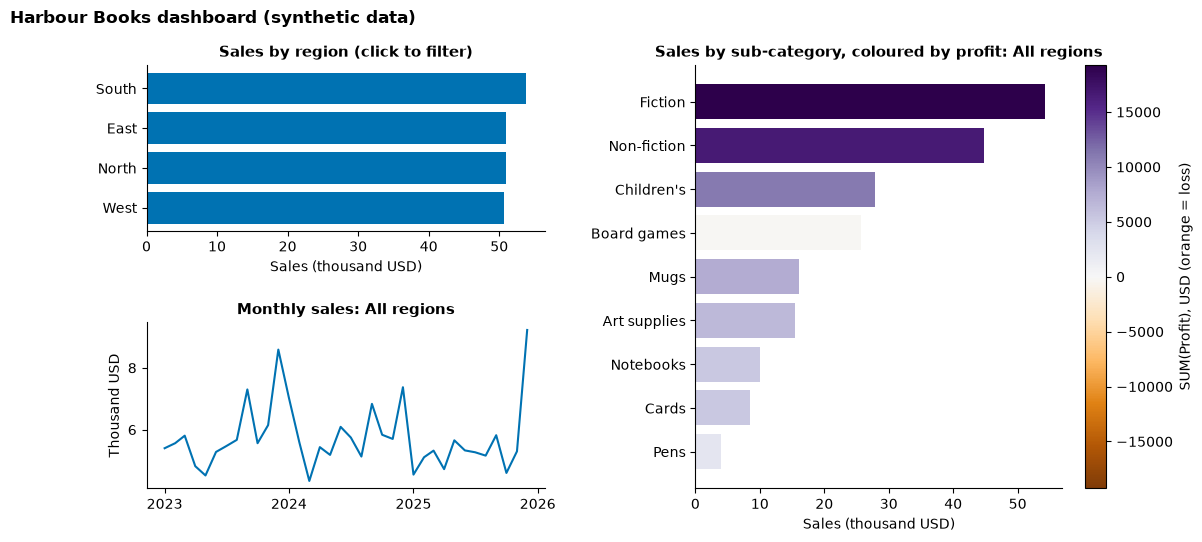

In [14]:
def harbour_dashboard(region=None):
    data = orders if region is None else orders[orders["region"] == region]
    label = "All regions" if region is None else region
    fig = plt.figure(figsize=(13, 5.5))
    gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.15], hspace=0.55, wspace=0.35)

    # View 1: the source sheet (regions), with the selection highlighted
    ax = fig.add_subplot(gs[0, 0])
    reg = orders.groupby("region")["sales"].sum().sort_values()
    ax.barh(reg.index, reg.values / 1000,
            color=[OI["blue"] if (region is None or r == region) else "#E5E5E5" for r in reg.index])
    ax.set_title("Sales by region (click to filter)"); ax.set_xlabel("Sales (thousand USD)")

    # View 2: monthly trend, continuous month
    ax = fig.add_subplot(gs[1, 0])
    trend = data.set_index("order_date")["sales"].resample("MS").sum()
    ax.plot(trend.index, trend.values / 1000, color=OI["blue"])
    ax.set_title(f"Monthly sales: {label}"); ax.set_ylabel("Thousand USD")
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

    # View 3: sales by sub-category (length), coloured by profit (diverging, centred at 0)
    ax = fig.add_subplot(gs[:, 1])
    sub = data.groupby("sub_category").agg(sales=("sales", "sum"), profit=("profit", "sum")).sort_values("sales")
    lim = max(abs(sub["profit"].min()), abs(sub["profit"].max()))
    norm = mcolors.TwoSlopeNorm(vmin=-lim, vcenter=0, vmax=lim)
    cmap = plt.get_cmap("PuOr")
    ax.barh(sub.index, sub["sales"] / 1000, color=cmap(norm(sub["profit"])))
    ax.set_title(f"Sales by sub-category, coloured by profit: {label}"); ax.set_xlabel("Sales (thousand USD)")
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    fig.colorbar(sm, ax=ax, label="SUM(Profit), USD (orange = loss)")
    fig.suptitle("Harbour Books dashboard (synthetic data)", x=0.02, ha="left", fontweight="bold")
    plt.show()

harbour_dashboard()

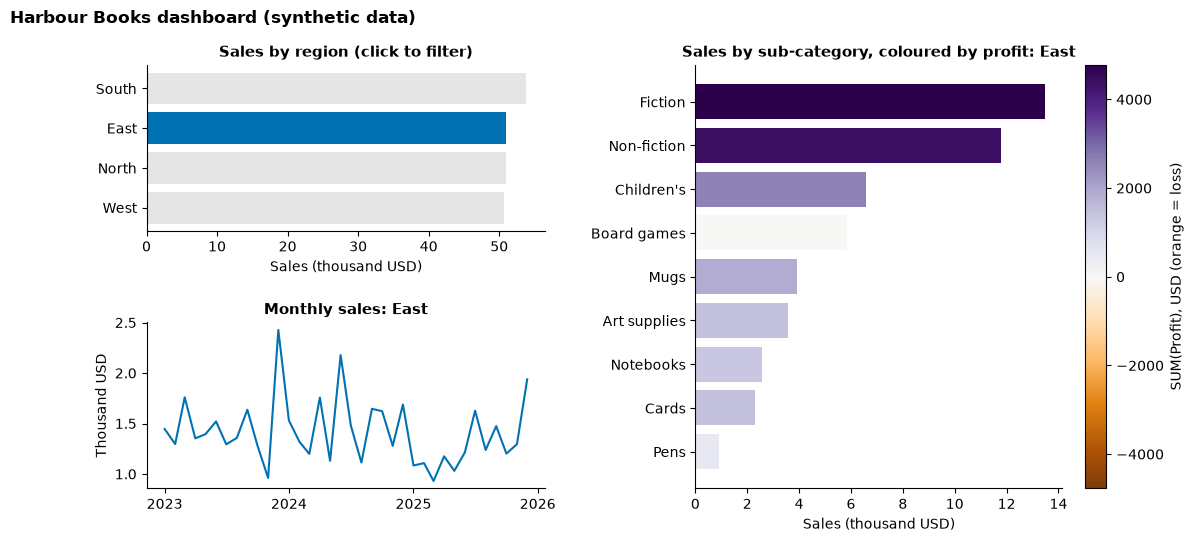

In [15]:
harbour_dashboard("East")   # like clicking East in the region view

> **Discuss.** In the right-hand chart, bar **length** shows sales and **colour** shows profit. Which encoding will a hurried reader look at first, and what might they miss? (This morning's lecture, Part 2, and the reading packet's section on dual encoding will help.)

Notice also: after filtering, the **colour scale was recomputed** from the filtered data, so the same shade can mean different amounts in the two pictures. Tableau behaves the same way unless you fix the colour range (**Edit Colors → Advanced → Start / End**). When comparing filtered views, read the values (tooltip or labels), not just the shade.

### Dashboard design checklist

Before you publish or print a dashboard, check:

- [ ] **Purpose:** one sentence says who it is for and which decision it supports; the title says it.
- [ ] **Priority:** the most important view or KPI is top-left; overview first, detail below.
- [ ] **Few views:** three to five, each with a message title.
- [ ] **Chart choice:** each view matches its question (Part 1 of the morning lecture); bars sorted when ranking.
- [ ] **Colour:** one meaning per colour across the dashboard; diverging measures centred at zero; colour-blind safe; never colour alone.
- [ ] **Numbers:** units and formats (US dollars, percentages) set in **Default Properties**; sensible rounding.
- [ ] **Interactivity:** actions tested; the instruction ("click a state…") is visible; clearing a selection returns to the full view.
- [ ] **Tooltips:** edited to read like a sentence, with units.
- [ ] **Size:** fixed size when the output is a PDF or a slide; checked at the size readers will use.
- [ ] **Static state:** before printing or exporting, the selection is **cleared** so the output shows the intended (usually unfiltered) view.
- [ ] **Test:** someone who did not build it can answer the intended question in under a minute.

---

## Part 9: Lab 2 briefing

In Lab 2 (periods 7 and 8) you build an executive summary dashboard in Tableau Desktop from **Sample – Superstore**: a monthly sales trend, a filled map of profit by state, and sales by sub-category coloured by profit, linked so that clicking a state filters the other two. You then use it to answer GAP's questions in a separate document and submit one combined PDF.

What from this lecture you will need:

| Lab step | Concept |
|---|---|
| The trend uses the **second** Month option, and the pill turns green | Part 2: continuous date values make a timeline |
| The map uses the **Map** mark type with Profit on Color | Parts 4 and 7: filled map, diverging colour centred at zero |
| Bars sorted, Profit on Color | Morning Part 1 (sorting) and Part 2 (two encodings) |
| The map becomes a filter for the other sheets | Part 8: **Use as Filter** creates a filter action |
| Print with nothing selected | Part 8 checklist: clear the selection |

The [Lab 2 guide](guides/lab2_dashboard.md) lists the steps, the version differences in Superstore (for example **State** or **State/Province**) and the known pitfalls. Your answers must come from **your own** dashboard: Superstore's figures differ between Tableau versions.

---

## Part 10: Assignment 1 briefing: reading box plots and regression lines

Assignment 1 (periods 9 and 10, due Sunday 15 November) asks you to run a given script on a restaurant's transaction data and write a four-section business report about its tables and three figures: a bar chart, a **box plot** and a **scatter plot with a regression line**. The [Assignment 1 guide](guides/assignment1_descriptive_report.md) gives the structure and report-writing advice. Here we practise the two harder readings on penguins, so the skill transfers but the answers do not.

### Reading a box plot in sentences

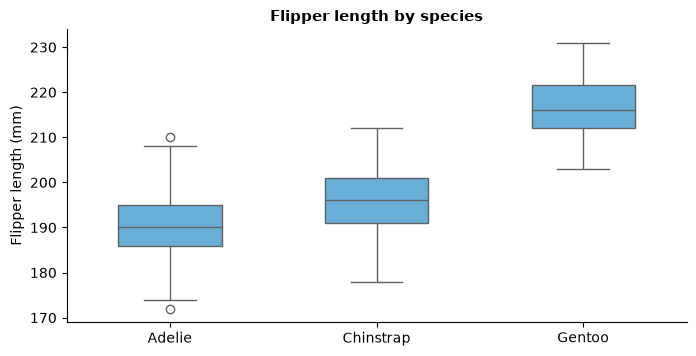

           count    25%    50%    75%   IQR
species                                    
Adelie     146.0  186.0  190.0  195.0   9.0
Chinstrap   68.0  191.0  196.0  201.0  10.0
Gentoo     119.0  212.0  216.0  221.5   9.5


In [16]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.boxplot(data=penguins, x="species", y="flipper_length_mm", order=["Adelie", "Chinstrap", "Gentoo"],
            color=OI["sky"], width=0.5, ax=ax)
ax.set_xlabel(""); ax.set_ylabel("Flipper length (mm)")
ax.set_title("Flipper length by species")
plt.show()

stats = penguins.groupby("species")["flipper_length_mm"].describe()[["count", "25%", "50%", "75%"]]
stats["IQR"] = stats["75%"] - stats["25%"]
print(stats.round(1).to_string())

A model paragraph (notice the numbers, the units and the comparison):

> *The typical Gentoo penguin has a flipper about 25 mm longer than the typical Adelie (medians of 216 mm and 190 mm). The middle half of each species spans only about 9 to 10 mm (the interquartile ranges), so the boxes do not overlap and flipper length alone separates Gentoo from the other two species well. Chinstrap and Adelie overlap heavily and could not be told apart by this measure. A few birds lie beyond the whiskers; they are unusual for their species rather than errors.*

The checklist behind it: (1) compare the **medians** with units; (2) compare the **spreads** (IQR, whisker length); (3) say whether the boxes **overlap** and what that means for the decision; (4) mention **outliers** and what they might be; (5) say how many observations each box rests on if they differ a lot.

### Reading a regression line in sentences

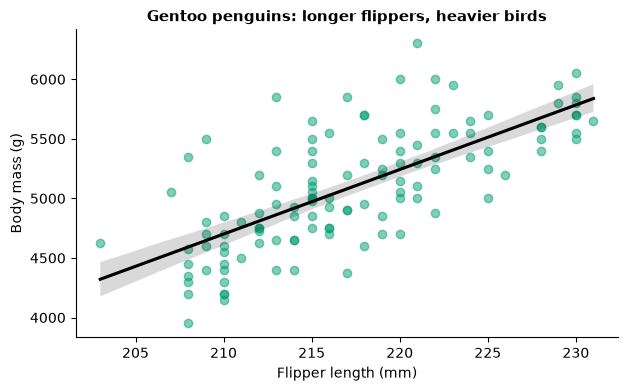

slope = 54.2 g per mm, intercept = -6674 g, r = 0.71, n = 119


In [17]:
gentoo = penguins[penguins["species"] == "Gentoo"]
slope, intercept = np.polyfit(gentoo["flipper_length_mm"], gentoo["body_mass_g"], 1)
r = gentoo["flipper_length_mm"].corr(gentoo["body_mass_g"])

fig, ax = plt.subplots(figsize=(7, 4))
sns.regplot(data=gentoo, x="flipper_length_mm", y="body_mass_g", ax=ax, seed=0,   # seed: the band is bootstrapped
            scatter_kws={"alpha": 0.5, "color": OI["green"]}, line_kws={"color": "black"})
ax.set_xlabel("Flipper length (mm)"); ax.set_ylabel("Body mass (g)")
ax.set_title("Gentoo penguins: longer flippers, heavier birds")
plt.show()
print(f"slope = {slope:.1f} g per mm, intercept = {intercept:.0f} g, r = {r:.2f}, n = {len(gentoo)}")

A model paragraph:

> *Among Gentoo penguins, each extra millimetre of flipper length goes with about 54 g more body mass on average (the slope of the fitted line), across flippers from about 205 to 230 mm. The points scatter widely around the line (r ≈ 0.7), so flipper length gives a useful but rough guide to an individual bird's mass. The relationship is an association: it does not show that longer flippers cause extra weight; both grow with the bird's overall size.*

The checklist: (1) state the **slope in words with both units** ("per mm", "per dollar"); (2) give the **range** of x over which it holds; do not extrapolate far beyond it; (3) say how **tightly** the points follow the line (r, or "wide scatter"); (4) say **association, not causation**, and name what else could explain it; (5) the shaded band around a seaborn regression line is a confidence band for the **line**, not a range for individual points. If the script you are given does not print the slope, you can read it from the chart: pick two points on the line far apart and divide the rise by the run.

**Do not** copy these paragraphs into Assignment 1: they are about penguins. Use the checklists on your own figures.

---

## Part 11: Practice, quiz and summary

### Practice

#### Core

**Core 1.** In Tableau with any data source (Superstore is fine for practice; do this **after** Lab 2), make the same view twice: once with discrete MONTH(Order Date) and once with continuous MONTH(Order Date). Write one question each view answers.

**Core 2.** Using `orders`, compute total sales and profit ratio (`SUM/SUM`) for each **category within each region** (level of detail = region × category). Which combination has the lowest profit ratio?

**Core 3.** Using `orders`, find the top 2 sub-categories by sales **within** the South (filter first, then rank, as a context filter would), and compare them with the top 2 for the whole chain.

#### Stretch

**Stretch 1.** Write the Tableau calculation for "share of a region's sales that came from discounted lines" and mirror it in pandas.

**Stretch 2.** Change `harbour_dashboard` so that the colour scale is **fixed** across all regions (compute `lim` from the full data). Compare the East view with the one above.

**Stretch 3.** Mirror an `EXCLUDE` expression: for each region × category mark, show the region's total sales next to the category's sales, and the category's share of its region.

#### Challenge

**Challenge 1.** Using `first_order_year`, build a cohort table: rows are the first-order year, columns are order years, values are distinct customers who ordered. What does the table say about customer retention at Harbour Books?

**Challenge 2.** Add a **highlight** behaviour to `harbour_dashboard`: instead of filtering the trend to one region, draw all four regions' trends in grey and the selected one in colour. When is highlight better than filter for a manager?

### Quiz

1. What is the difference between a dimension and a measure? Give one numeric field that should be a dimension.
2. What do blue and green pills mean? What does each create on the Columns shelf?
3. A line chart of monthly sales shows only 12 points for three years of data. What happened, and how do you fix it?
4. What sets the level of detail of a view? What happens to the marks when you drag a dimension onto Detail?
5. Why might `AVG([Sales])` not answer "what does an average customer spend?"
6. In which order does Tableau apply context filters, dimension filters and measure filters? Why does this matter for Top N?
7. Write the aggregate calculation for profit ratio, and explain why it differs from `AVG([Profit]/[Sales])`.
8. What does *Compute Using* control in a table calculation?
9. What does the **Use as Filter** icon create, and where can you edit it?
10. Give two reasons to clear the selection and use a fixed size before printing a dashboard to PDF.
11. In one sentence each, describe what the slope of a regression line and the box of a box plot tell a manager.

### Summary

| Idea | Remember |
|---|---|
| Building blocks | Data source → worksheets → dashboard → story; save `.twbx` to share |
| Roles | Dimensions group, measures aggregate; IDs and years are usually dimensions |
| Pill colour | Blue = discrete → headers; green = continuous → axis. Date parts vs date values |
| Aggregation | SUM by default; AVG is per row; COUNTD for distinct customers |
| Level of detail | Set by the dimensions in the view; FIXED / INCLUDE / EXCLUDE change it for one calculation |
| Marks | Mark type, Color, Size, Label, Detail, Tooltip; diverging colour centred at zero |
| Filters | Extract → data source → context → FIXED/Top N → dimension → INCLUDE/EXCLUDE → measure → table calcs |
| Calculations | Row-level vs aggregate; profit ratio = SUM/SUM; table calculations depend on Compute Using |
| Maps | Geographic roles; field names vary by version; filled maps favour big areas; map rates |
| Dashboards | Few views, clear purpose, visible instructions; filter and highlight actions; clear the selection before export |
| Reports | Box plot: medians, IQR, overlap, outliers. Regression: slope with units, range, scatter, association not cause |

**Next:** the [Lab 2 guide](guides/lab2_dashboard.md) (periods 7 and 8) and the [Assignment 1 guide](guides/assignment1_descriptive_report.md) (periods 9 and 10). Earlier today: [Visualising and communicating data](D2_lecture_visual_communication.md).

---

## For the facilitator

This notebook fills periods P5–P6 of Day 2 and the Assignment 1 briefing in P9. It is best taught with Tableau Desktop on the projector: demonstrate each concept in Tableau on a data source **other than Superstore** (for example a CSV of the `orders` table, exported with `orders.to_csv("harbour_books.csv", index=False)`), then show the Python mirror. No Lab 2 or Assignment 1 answers are given here.

| Period | Minutes | Content | Notes |
|---|---|---|---|
| P5 | 10 | Part 1: building blocks and the workspace | Open Tableau; name each area of the screen |
| P5 | 15 | Part 2: dimensions, measures, discrete and continuous dates | Build both date views live; ask the prediction about YEAR + MONTH as headers |
| P5 | 10 | Part 3: aggregation, level of detail, LOD expressions | Change SUM to AVG and COUNTD live; drag a dimension to Detail |
| P5 | 10 | Part 4: the Marks card | Set the profit colour centre to 0 live |
| P6 | 12 | Part 5: filters and the Top N surprise | Show the empty or short result, then Add to Context |
| P6 | 10 | Part 6: calculated fields, profit ratio, table calculations | Trigger the "cannot mix aggregate" error on purpose |
| P6 | 5 | Part 7: maps and geographic roles | Mention State vs State/Province |
| P6 | 10 | Part 8: dashboard, Use as Filter, checklist | Build a two-sheet dashboard with an action in five minutes |
| P6 | 8 | Part 9: Lab 2 briefing | Walk through the guide's pitfalls; check every student has Tableau activated |
| P7–P8 | 90 | **Lab 2** | Circulate; check the green Month pill, the Map mark type and the filter action |
| P9 | 30 | Part 10: Assignment 1 briefing, box plots and regression lines | Read the two penguin paragraphs aloud; students mark the checklist items in them |
| P9 | 15 | The [Assignment 1 guide](guides/assignment1_descriptive_report.md): headings, routes, pitfalls | Everyone runs Route A or B before P10 |
| P10 | 45 | Assignment 1 studio | Students draft their outline using the four headings; answer questions without giving values |

Practice and quiz are for self-study or faster groups.